# Sales Data Analysis with Pandas

**Objective:** Analyse the cleaned sales dataset from Task 1 (Data Cleaning) using pandas.
Calculate total sales, average order value and top products, and summarise sales by
product, city, month, payment method and order status.

**Dataset:** `data/Cleaned_Data.csv` — the cleaned output of Task 1 (466 orders).
No new data was invented. The 25 orders with a missing order date are excluded
only from the monthly analysis, not from the other totals.


In [6]:
# 1. Load the data
import pandas as pd
import re
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

# Use the cleaned file from Task 1, so this analysis starts from clean data taken from repository
url = "https://raw.githubusercontent.com/arooba2702/Data_Cleaning_Mini_Project/refs/heads/main/Cleaned_Data.csv"
df = pd.read_csv(url)
print(df.shape)
print(df.head())
print(df.dtypes)


(466, 13)
   Order ID Customer Name                       Email         Phone  Age  \
0      1001  Danish Malik    danish.malik72@yahoo.com  0344-7038374   55   
1      1002    Hina Tariq      hina.tariq74@yahoo.com  0300-3823498   23   
2      1003    Zain Iqbal      zain.iqbal30@gmail.com  0345-4491946   44   
3      1004  Bilal Sheikh     bilal.sheikh88@mail.com  0345-6402509   47   
4      1005  Kamran Malik  kamran.malik70@outlook.com  0333-8197443   44   

         City  Product  Order Date  Quantity  Unit Price   Amount  \
0     Unknown   Laptop  2026-03-23         1     1219.09  1219.00   
1  Faisalabad  Monitor  2026-07-14         3      151.92   456.00   
2  Faisalabad    Mouse  2026-04-19         2       47.34    94.68   
3      Lahore    Mouse  2026-01-06         1       31.58    31.58   
4   Islamabad   Tablet         NaN         1      345.64   346.00   

     Payment Method     Status  
0       Credit Card    Shipped  
1  Cash on Delivery    Shipped  
2         Easypaisa

## 2. Key metrics

In [11]:
# 2. Key metrics

# Make sure Order Date is a real datetime (CSV files store dates as text)
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')

total_orders = len(df)
total_sales = df['Amount'].sum()
average_order_value = df['Amount'].mean()
total_quantity = df['Quantity'].sum()

print(f'Total orders: {total_orders}')
print(f'Total sales (all statuses): {total_sales:,.2f}')
print(f'Average order value: {average_order_value:,.2f}')
print(f'Total quantity sold: {total_quantity}')
print(f'Average quantity per order: {df["Quantity"].mean():.2f}')

# Date range (guarded in case every date failed to parse)
if df['Order Date'].notna().any():
    print(f'Date range: {df["Order Date"].min().date()} to {df["Order Date"].max().date()}')
else:
    print('Date range: no valid dates found')

print(f'Orders with missing date: {df["Order Date"].isna().sum()}')

Total orders: 466
Total sales (all statuses): 316,910.42
Average order value: 680.07
Total quantity sold: 824
Average quantity per order: 1.77
Date range: 2026-01-02 to 2026-09-27
Orders with missing date: 25


## 3. Sales by product — which products earn the most?

            Total Sales  Orders  Average Order Value
Product                                             
Laptop        144470.78      81              1783.59
Phone          74203.84      70              1060.05
Monitor        41374.69      79               523.73
Tablet         33209.15      46               721.94
Headphones     10054.00      56               179.54
Keyboard        6411.65      66                97.15
Unknown         3997.72       6               666.29
Mouse           3188.59      62                51.43


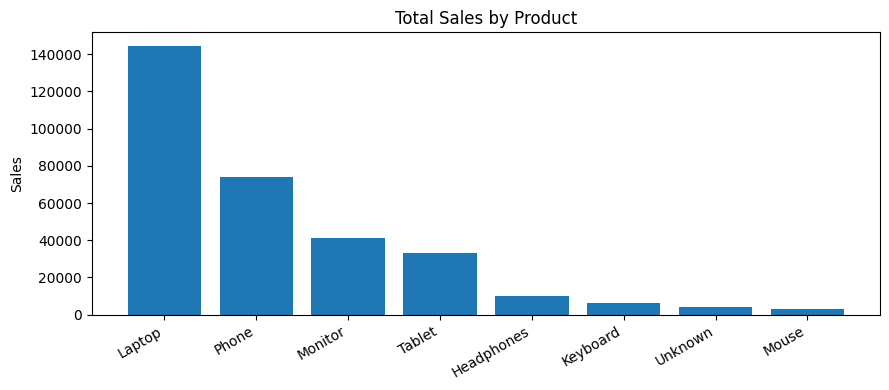

In [12]:
# 3. Sales by product
by_product = df.groupby('Product')['Amount'].agg(['sum', 'count', 'mean'])
by_product.columns = ['Total Sales', 'Orders', 'Average Order Value']
by_product = by_product.sort_values('Total Sales', ascending=False)
print(by_product.round(2))

plt.figure(figsize=(9, 4))
plt.bar(by_product.index, by_product['Total Sales'])
plt.title('Total Sales by Product')
plt.ylabel('Sales')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 4. Sales by city — which regions buy the most?

            Total Sales  Orders  Average Order Value
City                                                
Rawalpindi     71229.34      88               809.42
Faisalabad     61216.48      91               672.71
Karachi        58742.36      86               683.05
Islamabad      52692.50      92               572.74
Lahore         49412.46      87               567.96
Unknown        23617.28      22              1073.51


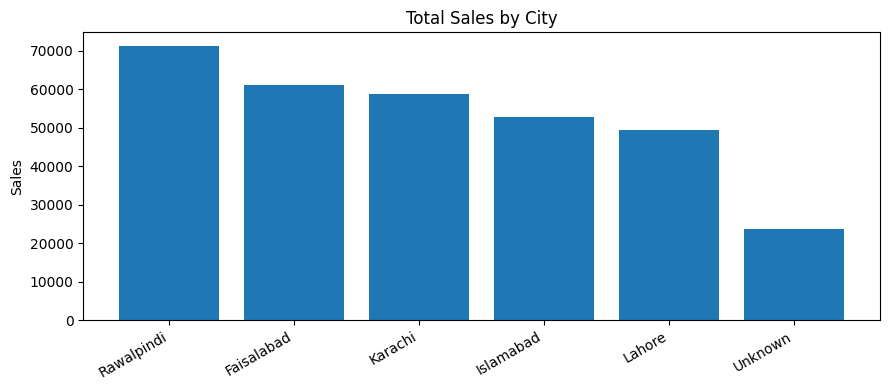

In [13]:
# 4. Sales by city
by_city = df.groupby('City')['Amount'].agg(['sum', 'count', 'mean'])
by_city.columns = ['Total Sales', 'Orders', 'Average Order Value']
by_city = by_city.sort_values('Total Sales', ascending=False)
print(by_city.round(2))

plt.figure(figsize=(9, 4))
plt.bar(by_city.index, by_city['Total Sales'])
plt.title('Total Sales by City')
plt.ylabel('Sales')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 5. Sales over time — monthly trend (25 orders without a date are excluded here only)

         Total Sales  Orders  Average Order Value
Month                                            
2026-01     33086.48      48               689.30
2026-02     24458.36      45               543.52
2026-03     44816.55      55               814.85
2026-04     21506.54      42               512.06
2026-05     28091.83      51               550.82
2026-06     55415.64      62               893.80
2026-07     33953.27      48               707.36
2026-08     27026.38      42               643.49
2026-09     32854.02      48               684.46


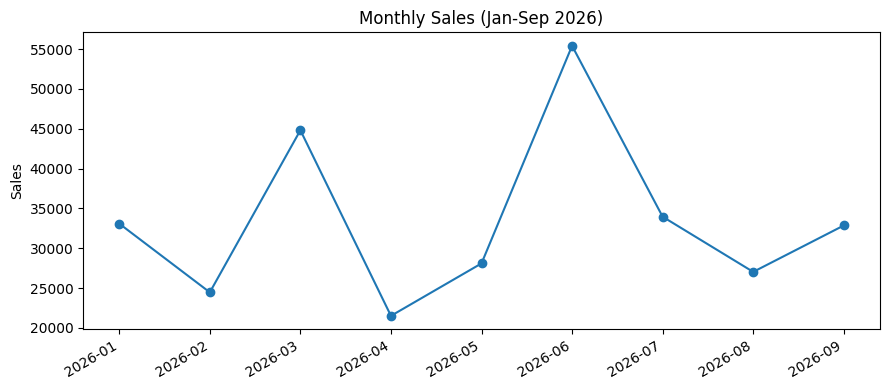

In [14]:
# 5. Sales by month
df['Month'] = df['Order Date'].dt.to_period('M').astype(str)
by_month = df.dropna(subset=['Order Date']).groupby('Month')['Amount'].agg(['sum', 'count', 'mean'])
by_month.columns = ['Total Sales', 'Orders', 'Average Order Value']
print(by_month.round(2))

plt.figure(figsize=(9, 4))
plt.plot(by_month.index, by_month['Total Sales'], marker='o')
plt.title('Monthly Sales (Jan-Sep 2026)')
plt.ylabel('Sales')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 6. Sales by payment method and by status

In [15]:
# 6a. Sales by payment method
by_payment = df.groupby('Payment Method')['Amount'].agg(['sum', 'count'])
by_payment.columns = ['Total Sales', 'Orders']
print(by_payment.sort_values('Total Sales', ascending=False).round(2))

# 6b. Sales by order status
# Important: 'Total sales' above includes Cancelled and Returned orders.
# Completed orders alone are the sales that were actually fulfilled.
by_status = df.groupby('Status')['Amount'].agg(['sum', 'count'])
by_status.columns = ['Total Sales', 'Orders']
print(by_status.sort_values('Total Sales', ascending=False).round(2))
print(f"Completed-only sales: {df[df['Status'] == 'Completed']['Amount'].sum():,.2f}")
print(f"Cancelled share of recorded sales: {df[df['Status'] == 'Cancelled']['Amount'].sum() / total_sales * 100:.1f}%")


                  Total Sales  Orders
Payment Method                       
Credit Card          81167.63     129
Easypaisa            53311.61      65
JazzCash             52927.51      75
Cash on Delivery     47362.07      64
Cash                 39167.75      76
Bank Transfer        32581.32      37
Unknown              10392.53      20
           Total Sales  Orders
Status                        
Cancelled     89730.34     126
Completed     86842.34     124
Pending       52424.89      75
Shipped       51180.82      93
Returned      22673.83      37
Unknown       14058.20      11
Completed-only sales: 86,842.34
Cancelled share of recorded sales: 28.3%


## 7. Findings

1. **Total recorded sales are 316,910.42 across 466 orders**, with an average order value of **680.07**.
2. **Laptop is the clear top product** at 144,470.78 (45.6% of recorded sales), followed by Phone at 74,203.84. Mouse and Keyboard sell often but at low prices, so their sales totals are small.
3. **Rawalpindi leads by city** at 71,229.34, closely followed by Faisalabad and Karachi. No single city dominates — sales are spread fairly evenly.
4. **June 2026 was the strongest month** (55,415.64) and April the weakest (21,506.54), so sales vary a lot month to month.
5. **Cancelled orders are a warning sign:** 89,730.34 (28.3% of recorded sales) was cancelled. Completed-only sales are 86,842.34, so the headline total should not be read as money actually earned.
6. **Credit Card is the most used payment method** by sales (81,167.63), followed by Easypaisa and JazzCash.

## Limitations
- 25 orders have no order date, so the monthly chart covers 441 dated orders.
- 'Unknown' product, city and payment values remain in the cleaned data where the original value could not be recovered.
- This is a small, synthetic sample dataset, so the findings describe this sample only — they are not a market forecast.


In [17]:
# 8. Save the summary tables for the report
import os

# Create the output folder if it doesn't already exist
os.makedirs('output', exist_ok=True)

by_product.round(2).to_csv('output/sales_by_product.csv')
by_city.round(2).to_csv('output/sales_by_city.csv')
by_month.round(2).to_csv('output/sales_by_month.csv')
by_status.round(2).to_csv('output/sales_by_status.csv')
by_payment.round(2).to_csv('output/sales_by_payment.csv')

print('Saved: output/sales_by_*.csv')
print(sorted(os.listdir('output')))


Saved: output/sales_by_*.csv
['sales_by_city.csv', 'sales_by_month.csv', 'sales_by_payment.csv', 'sales_by_product.csv', 'sales_by_status.csv']


## 8. Download the Files

In [18]:
import shutil
from google.colab import files

shutil.make_archive('output', 'zip', 'output')
files.download('output.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>